# Circumcenter of a Triangle

The **circumcenter** is the point that is the same distance from all three vertices.
It's where the three **perpendicular bisectors** of the sides meet, and it's the center of the circle that passes through all three vertices (the *circumcircle*).

**Steps:**
1. Take the 3 vertices A, B, C.
2. Compute `D = 2·(Ax(By−Cy) + Bx(Cy−Ay) + Cx(Ay−By))`. If `D = 0`, the points are on a line and there's no triangle.
3. Plug into the formula below to get the center (Ux, Uy).

In [1]:
import math
import matplotlib.pyplot as plt

def circumcenter(A, B, C):
    """Return the circumcenter (x, y) of triangle ABC.

    A, B, C are (x, y) tuples. Raises ValueError if the points are collinear.
    """
    ax, ay = A
    bx, by = B
    cx, cy = C

    D = 2 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    if math.isclose(D, 0, abs_tol=1e-12):
        raise ValueError("Points are collinear - no circumcenter exists.")

    a2 = ax**2 + ay**2
    b2 = bx**2 + by**2
    c2 = cx**2 + cy**2

    ux = (a2 * (by - cy) + b2 * (cy - ay) + c2 * (ay - by)) / D
    uy = (a2 * (cx - bx) + b2 * (ax - cx) + c2 * (bx - ax)) / D
    return (ux, uy)

## Example
A right triangle with vertices (0, 0), (4, 0), (0, 3). For a right triangle the circumcenter is the midpoint of the hypotenuse, so we expect **(2, 1.5)**.

In [2]:
A, B, C = (0, 0), (4, 0), (0, 3)
U = circumcenter(A, B, C)
print("Circumcenter:", U)

# Check: the distance to each vertex should be the same
for name, P in zip("ABC", (A, B, C)):
    print(f"Distance to {name}:", math.dist(U, P))

Circumcenter: (2.0, 1.5)
Distance to A: 2.5
Distance to B: 2.5
Distance to C: 2.5


## Picture it
The triangle, its circumcenter, and the circumcircle.

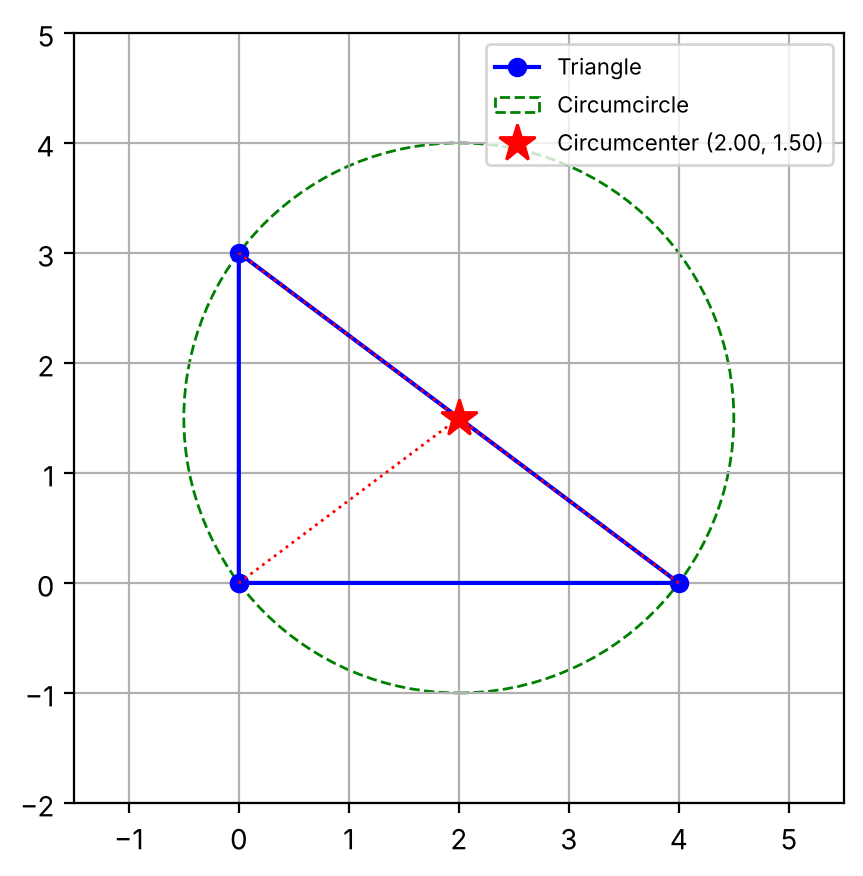

In [3]:
def plot_circumcircle(A, B, C):
    U = circumcenter(A, B, C)
    r = math.dist(U, A)

    fig, ax = plt.subplots(figsize=(5, 5))
    xs = [A[0], B[0], C[0], A[0]]
    ys = [A[1], B[1], C[1], A[1]]
    ax.plot(xs, ys, "b-o", label="Triangle")
    ax.add_patch(plt.Circle(U, r, fill=False, color="green", ls="--", label="Circumcircle"))
    ax.plot(*U, "r*", markersize=14, label=f"Circumcenter ({U[0]:.2f}, {U[1]:.2f})")
    for P in (A, B, C):
        ax.plot([U[0], P[0]], [U[1], P[1]], "r:", lw=1)  # equal radii
    ax.set_aspect("equal")
    ax.set_xlim(U[0] - r - 1, U[0] + r + 1)
    ax.set_ylim(U[1] - r - 1, U[1] + r + 1)
    ax.grid(True)
    ax.legend(loc="upper right", fontsize=8)
    plt.show()

plot_circumcircle((0, 0), (4, 0), (0, 3))

## Try your own
An obtuse triangle — notice the circumcenter lands **outside** the triangle.

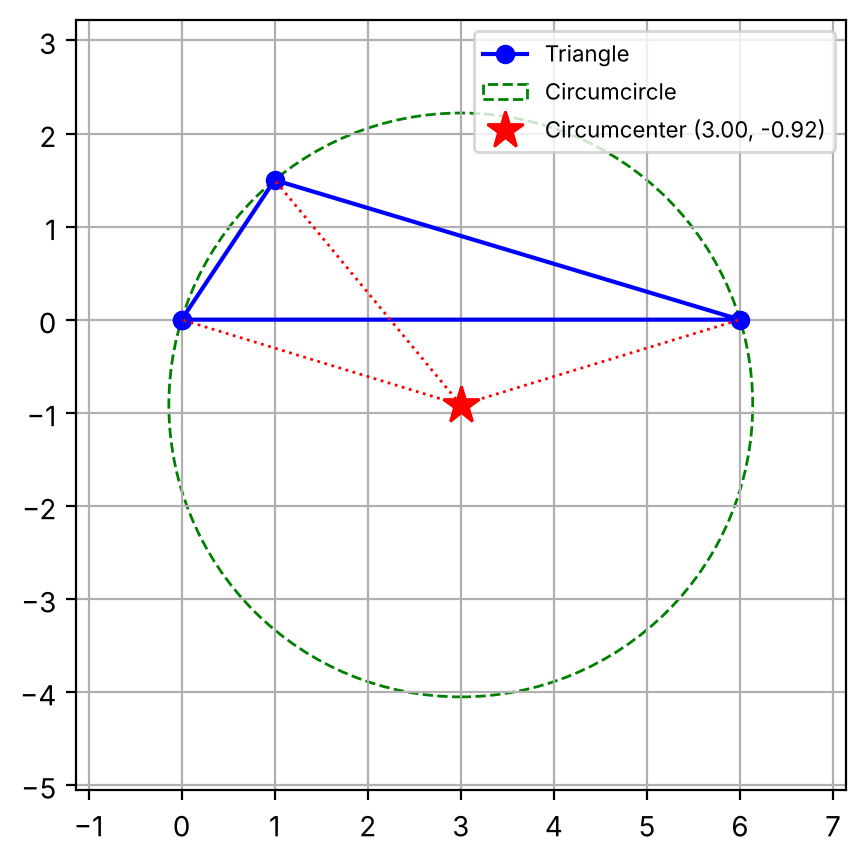

In [4]:
plot_circumcircle((0, 0), (6, 0), (1, 1.5))

## Collinear points
If the 3 points are on a line, there is no triangle, so the function raises an error.

In [5]:
try:
    circumcenter((0, 0), (1, 1), (2, 2))
except ValueError as e:
    print("Error:", e)

Error: Points are collinear - no circumcenter exists.
